# Rossmann Store Sales: Exploratory Data Analysis (Task 1)
NextHikes Project 6. Goal: understand customer purchasing behaviour, and check how promos, holidays, assortment and competition affect sales.

**Contents:** 0 Setup and cleaning · 1 Train vs test · 2 Holidays and seasonality · 3 Sales vs customers · 4 Promos · 5 Opening days · 6 Assortment · 7 Competition · 8 Correlations

## 0. Setup, logging and data cleaning

In [1]:
import sys, warnings; sys.path.insert(0, "..")
import os; os.chdir("..")                      # run from project root
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.logger import get_logger
from src.data import load_raw, clean_store, clean_sales, flag_outliers, merge_store
from src.features import add_date_features, add_store_features, holiday_dates
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
log = get_logger("rossmann.eda")
def save(name): plt.tight_layout(); plt.savefig(f"figures/{name}.png", bbox_inches="tight"); plt.show()

train_raw, test_raw, store_raw = load_raw("data")
print("Missing values (raw):"); print(train_raw.isna().sum().sum(), "in train |", test_raw.isna().sum()[lambda s: s>0].to_dict(), "in test")
print(store_raw.isna().sum()[lambda s: s>0])

2026-11-07 09:37:11,732 | INFO | rossmann.data | Loaded train (1017209, 9), test (41088, 8), store (1115, 10)


Missing values (raw):
0 in train | {'Open': 11} in test
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64


In [2]:
store = clean_store(store_raw)
train, test = clean_sales(train_raw), clean_sales(test_raw, is_train=False)
train["SalesOutlier"] = flag_outliers(train)
hol = holiday_dates(train, test)
train = add_store_features(add_date_features(merge_store(train, store), hol))
test  = add_store_features(add_date_features(merge_store(test, store), hol))
log.info("EDA frames ready: train %s test %s", train.shape, test.shape)
opn = train[train.Open == 1]            # open days only, used for most sales analysis
print(f"Open days: {len(opn):,} of {len(train):,} rows | outliers flagged: {train.SalesOutlier.sum():,}")

2026-11-07 09:37:11,773 | INFO | rossmann.data | clean_store: filled 3 missing CompetitionDistance values (median)


2026-11-07 09:37:11,845 | INFO | rossmann.data | Dropping 54 rows where store was open but Sales == 0 (data errors)


2026-11-07 09:37:11,888 | INFO | rossmann.data | Filled 11 missing Open values with 1


2026-11-07 09:37:12,036 | INFO | rossmann.data | Flagged 1113 Sales outliers (IQR x 3.0 per store)


2026-11-07 09:37:16,709 | INFO | rossmann.eda | EDA frames ready: train (1017155, 36) test (41088, 34)


Open days: 844,338 of 1,017,155 rows | outliers flagged: 1,113


**Cleaning decisions**
- `CompetitionDistance`: 3 missing → median + a flag column.
- `CompetitionOpenSince*` / `Promo2*`: NaN means *no known date* / *not in Promo2* → filled with 0 plus flags.
- Test `Open`: 11 missing rows (store 622) → assumed open.
- 54 train rows are open with 0 sales → dropped as data errors. Days when a store is closed legitimately have 0 sales; they are kept for opening-pattern analysis but excluded from sales comparisons.
- Outliers: per-store IQR×3 rule on open days. They are **flagged, not removed**, because the biggest ones are real Christmas/promo peaks.

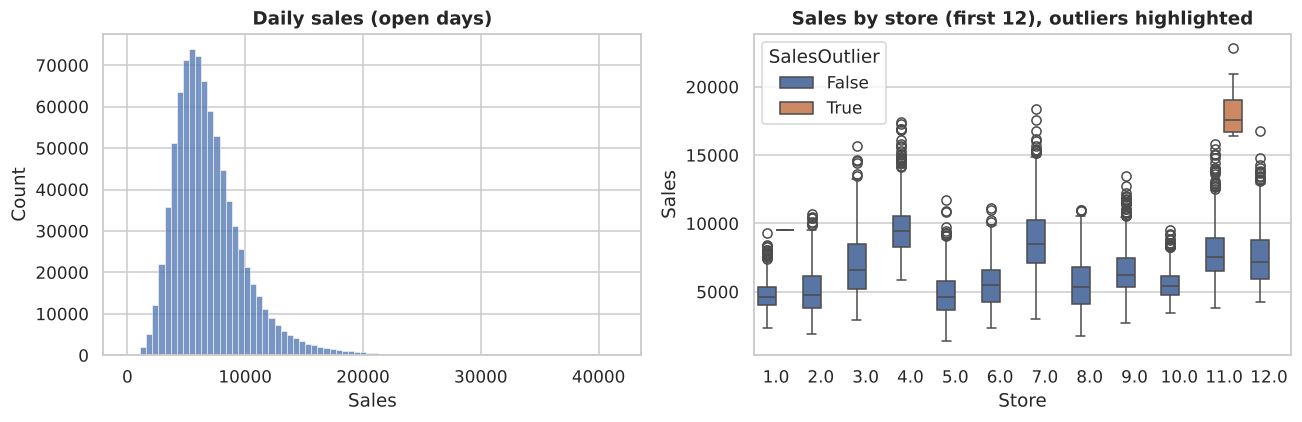

                 count     mean     std    min      25%      50%      75%  \
SalesOutlier                                                                
False         843225.0   6943.0  3080.0   46.0   4857.0   6365.0   8349.0   
True            1113.0  16439.0  5478.0  133.0  12556.0  15886.0  19217.0   

                  max  
SalesOutlier           
False         38025.0  
True          41551.0  
Outlier months:
{12: 725, 6: 118, 3: 42, 8: 40, 4: 34}


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(opn.Sales, bins=80, ax=ax[0]); ax[0].set_title("Daily sales (open days)")
sns.boxplot(x=opn.loc[opn.Store.isin(range(1, 13)), "Store"], y=opn.Sales, ax=ax[1], hue=opn.loc[opn.Store.isin(range(1,13)), "SalesOutlier"]); ax[1].set_title("Sales by store (first 12), outliers highlighted")
save("00_sales_distribution")
print(opn.groupby("SalesOutlier").Sales.describe().round(0))
print("Outlier months:"); print(opn[opn.SalesOutlier].Month.value_counts().head(5).to_dict())

**Insight:** Sales are right-skewed (median ≈ 6.4k, max ≈ 41k). The 1,113 flagged outliers average ≈ 16k, and **725 of them fall in December**. They are genuine Christmas peaks, so they are kept and flagged rather than deleted. Tree models handle them well; for the LSTM, consider a log transform.

## 1. Are the train and test sets distributed similarly?

          train  test
No promo   61.8  60.4
Promo      38.2  39.6
SchoolHoliday | train: {0: 82.1, 1: 17.9} | test: {0: 55.7, 1: 44.3}
DayOfWeek | train: {1: 14.2, 2: 14.3, 3: 14.3, 4: 14.3, 5: 14.3, 6: 14.2, 7: 14.2} | test: {1: 14.6, 2: 14.6, 3: 14.6, 4: 14.6, 5: 12.5, 6: 14.6, 7: 14.6}
Open | train: {0: 17.0, 1: 83.0} | test: {0: 14.6, 1: 85.4}


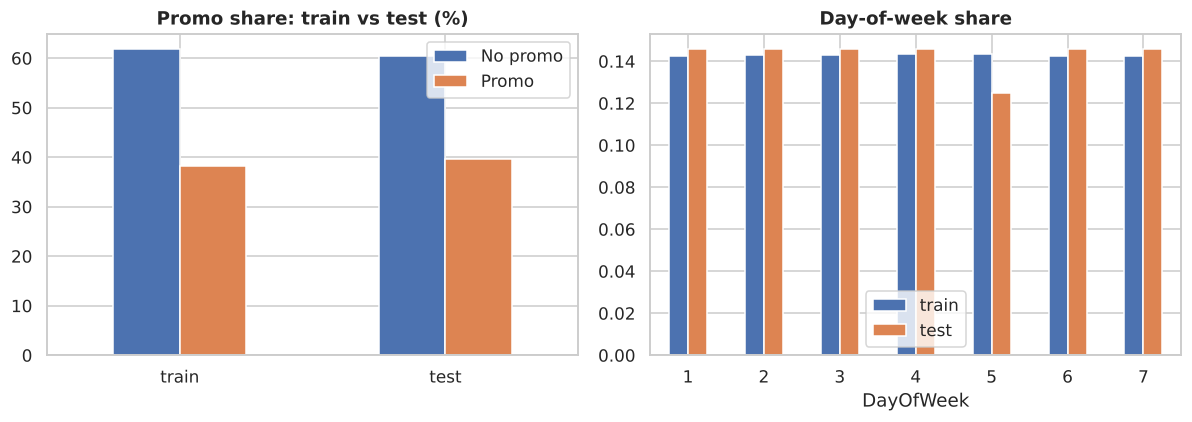

Stores in test but not train: set() | train period: 2013-01-01 → 2015-07-31 | test: 2015-08-01 → 2015-09-17


In [4]:
cmp = pd.DataFrame({"train": train.groupby("Promo").size() / len(train), "test": test.groupby("Promo").size() / len(test)})
cmp.index = ["No promo", "Promo"]; print((cmp*100).round(1))
for c in ["SchoolHoliday", "DayOfWeek", "Open"]:
    print(c, "| train:", (train[c].value_counts(normalize=True)*100).round(1).sort_index().to_dict(), "| test:", (test[c].value_counts(normalize=True)*100).round(1).sort_index().to_dict())
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
(cmp*100).T.plot(kind="bar", ax=ax[0], rot=0); ax[0].set_title("Promo share: train vs test (%)")
pd.DataFrame({"train": train.DayOfWeek.value_counts(normalize=True).sort_index(), "test": test.DayOfWeek.value_counts(normalize=True).sort_index()}).plot(kind="bar", ax=ax[1], rot=0); ax[1].set_title("Day-of-week share")
save("01_train_test_promo")
print("Stores in test but not train:", set(test.Store) - set(train.Store), "| train period:", train.Date.min().date(), "→", train.Date.max().date(), "| test:", test.Date.min().date(), "→", test.Date.max().date())

**Insight:** Promo share is very similar (38.2% train vs 39.6% test) and the weekday mix is balanced, so promo behaviour is comparable. Two differences matter for modelling: (1) **SchoolHoliday is 17.9% in train but 44.3% in test**. The test window (Aug-Sep 2015) overlaps summer school holidays, so we should validate on a similar time slice. (2) The test set is the **6 weeks right after the training data** (1 Aug - 17 Sep 2015), so a time-based split is the right validation strategy. All test stores exist in train.

## 2. Holidays and seasonality

                rows  pct_open  avg_sales_open
StateHoliday                                  
None          986105      0.86         6953.96
Public         20260      0.03         8487.47
Easter          6690      0.02         9887.89
Christmas       4100      0.02         9743.75


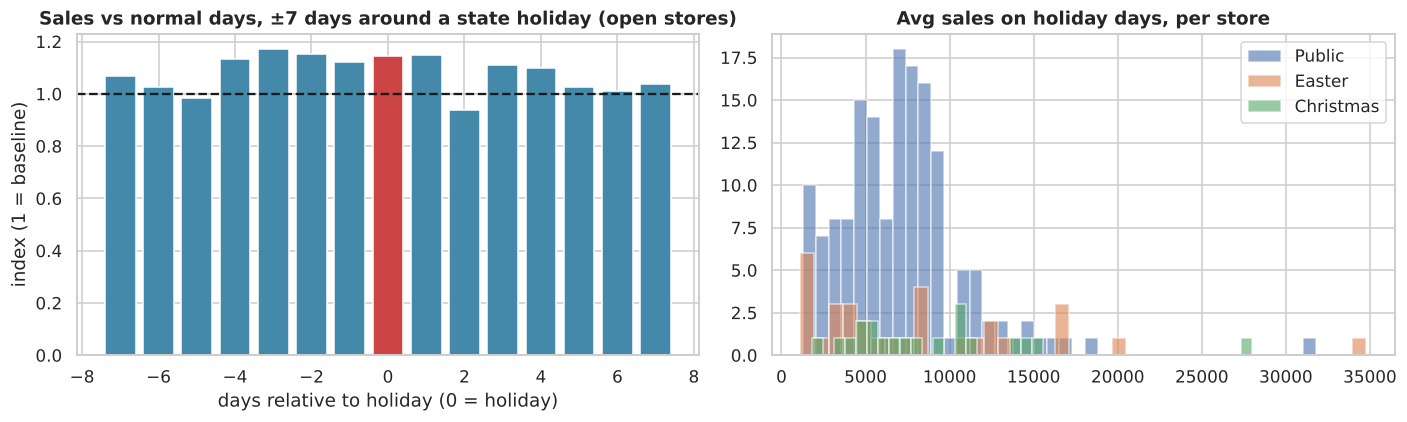

{-7.0: 1.07, -6.0: 1.03, -5.0: 0.98, -4.0: 1.13, -3.0: 1.17, -2.0: 1.15, -1.0: 1.12, 0.0: 1.14, 1.0: 1.15, 2.0: 0.94, 3.0: 1.11, 4.0: 1.1, 5.0: 1.03, 6.0: 1.01, 7.0: 1.04}


In [5]:
hol_type = train.groupby("StateHoliday").agg(rows=("Sales","size"), pct_open=("Open","mean"), avg_sales_open=("Sales", lambda s: s[s>0].mean())).round(2)
hol_type.index = hol_type.index.map({"0":"None","a":"Public","b":"Easter","c":"Christmas"}); print(hol_type)
# Before / during / after a state holiday
ba = opn.assign(rel=np.where(opn.StateHoliday != "0", 0, np.where(opn.DaysToHoliday <= 7, -opn.DaysToHoliday, np.where(opn.DaysAfterHoliday <= 7, opn.DaysAfterHoliday, np.nan))))
ba = ba.dropna(subset=["rel"]); prof = ba.groupby("rel").Sales.mean()
base = opn[(opn.DaysToHoliday > 7) & (opn.DaysAfterHoliday > 7)].Sales.mean()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(prof.index, prof.values / base, color=["#c44" if i == 0 else "#48a" for i in prof.index]); ax[0].axhline(1, c="k", ls="--"); ax[0].set_title("Sales vs normal days, ±7 days around a state holiday (open stores)"); ax[0].set_xlabel("days relative to holiday (0 = holiday)"); ax[0].set_ylabel("index (1 = baseline)")
for t, n in [("a","Public"),("b","Easter"),("c","Christmas")]:
    s = opn[opn.StateHoliday == t].groupby("Store").Sales.mean(); ax[1].hist(s, bins=40, alpha=.6, label=n)
ax[1].legend(); ax[1].set_title("Avg sales on holiday days, per store"); save("02_holiday_effect")
print((prof / base).round(2).to_dict())

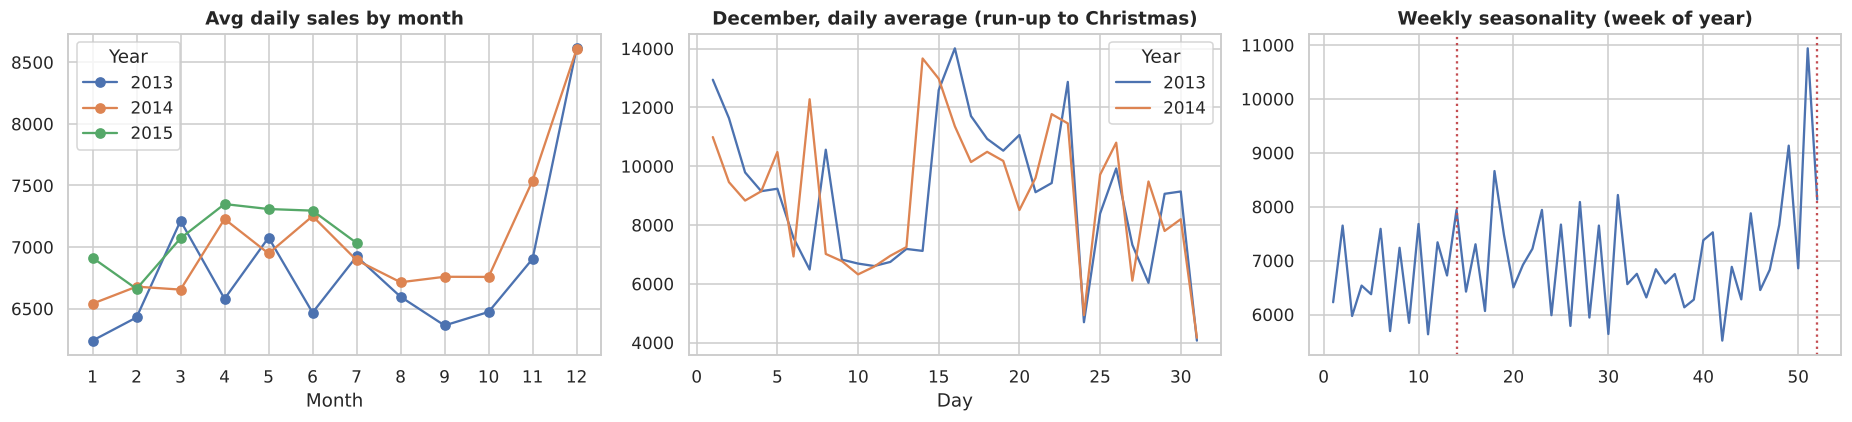

Avg sales by month: {1: 6564.0, 2: 6589.0, 3: 6977.0, 4: 7047.0, 5: 7107.0, 6: 7001.0, 7: 6954.0, 8: 6649.0, 9: 6547.0, 10: 6603.0, 11: 7189.0, 12: 8609.0}


In [6]:
# Seasonality: monthly profile, Christmas run-up and Easter
m = train[train.Open==1].groupby(["Year","Month"]).Sales.mean().unstack(0)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
m.plot(ax=ax[0], marker="o"); ax[0].set_title("Avg daily sales by month"); ax[0].set_xticks(range(1,13))
dec = opn[opn.Month == 12].groupby(["Year","Day"]).Sales.mean().unstack(0); dec.plot(ax=ax[1]); ax[1].set_title("December, daily average (run-up to Christmas)")
wk = opn.groupby("WeekOfYear").Sales.mean(); ax[2].plot(wk.index, wk.values); ax[2].set_title("Weekly seasonality (week of year)")
for e in [14, 52]: ax[2].axvline(e, c="r", ls=":")
save("03_seasonality")
print("Avg sales by month:", opn.groupby("Month").Sales.mean().round(0).to_dict())

**Insight:**
- **Stores are almost always closed on state holidays** (only 2-3% open). The few that open sell much more (Public ≈ 8.5k, Easter ≈ 9.9k, Christmas ≈ 9.7k vs ≈ 7.0k normal), but this is a selection effect (special locations such as stations/malls), not a general holiday boost.
- **Before / during / after:** sales run **≈ 12-17% above normal in the 4 days before a holiday** (stock-up behaviour) and there is a dip around 2 days after.
- **Seasonality:** December is the clear peak (≈ 8.6k vs ≈ 6.5-7.1k in other months, about +25%), with a rise from November. January-February and Aug-Oct are the weakest months. In December, sales peak in the run-up (mid-month and just before Christmas) and fall off sharply on the 24th-25th as stores close. Weeks 50-52 stand out in the weekly view, while Easter shows only a small bump.

## 3. Sales and number of customers

Pearson r (open days): 0.824 | Spearman: 0.832


{'a': 0.903, 'b': 0.871, 'c': 0.89, 'd': 0.858}


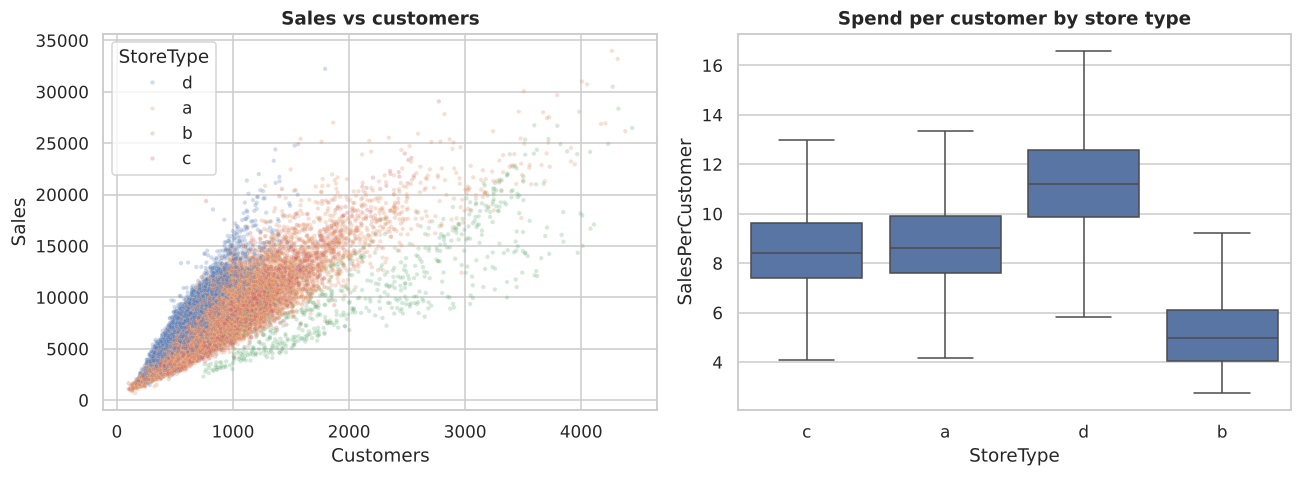

{'a': 8.85, 'b': 5.13, 'c': 8.63, 'd': 11.28}


In [7]:
print("Pearson r (open days):", round(opn.Sales.corr(opn.Customers), 3), "| Spearman:", round(opn.Sales.corr(opn.Customers, method="spearman"), 3))
print(opn.groupby("StoreType").apply(lambda d: d.Sales.corr(d.Customers)).round(3).to_dict())
opn = opn.assign(SalesPerCustomer = opn.Sales / opn.Customers.replace(0, np.nan))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
s = opn.sample(40000, random_state=1); sns.scatterplot(data=s, x="Customers", y="Sales", hue="StoreType", alpha=.25, s=8, ax=ax[0]); ax[0].set_title("Sales vs customers")
sns.boxplot(data=opn, x="StoreType", y="SalesPerCustomer", ax=ax[1], showfliers=False); ax[1].set_title("Spend per customer by store type")
save("04_sales_vs_customers"); print(opn.groupby("StoreType").SalesPerCustomer.mean().round(2).to_dict())

**Insight:** Sales and customers are **strongly correlated (r ≈ 0.82)**, so footfall drives revenue. The relationship differs by store type: spend per customer is lowest in type **b** (≈ 5.1) and highest in type **d** (≈ 11.3). ⚠️ `Customers` is **not available in the test set**, so it cannot be used as a feature. For the web app that must also predict customers, we need a separate customers model.

## 4. Promotions

         sales  customers    spc
Promo                           
0      5929.83     696.91   8.94
1      8228.74     844.48  10.18
Uplift (all open days): sales +38.8%, customers +21.2%, spend/customer +13.9%
Promo runs on: {1: 54.0, 2: 53.0, 3: 53.0, 4: 53.0, 5: 53.0, 6: 0.0, 7: 0.0} (% of store-days, Mon..Sun) -> promos only run Mon-Fri
Uplift (Mon-Fri only, like-for-like): sales +38.8%, customers +19.8%, spend/customer +15.3%


Sales uplift by weekday (%): {1: 57.1, 2: 44.8, 3: 36.8, 4: 32.1, 5: 22.1}


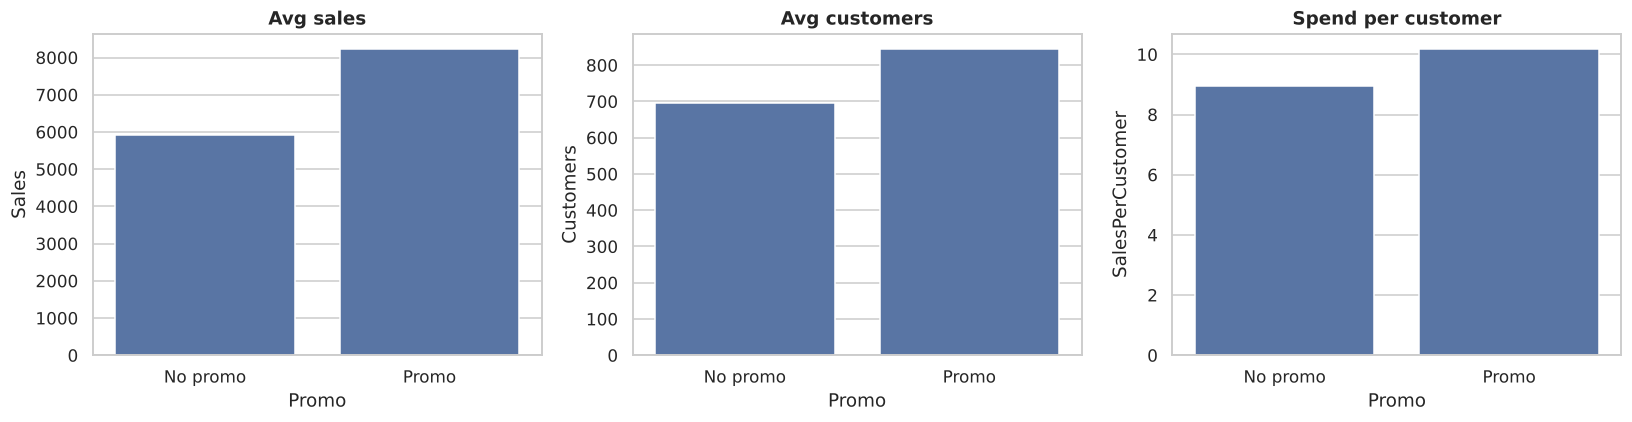

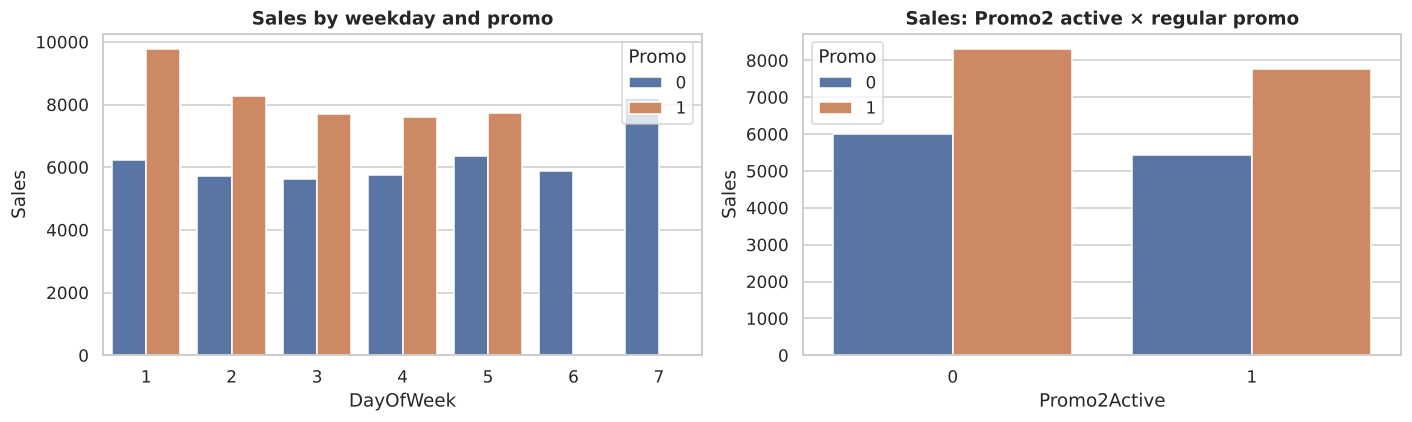

{0: {0: 6328.0, 1: 5530.0}, 1: {0: 8618.0, 1: 7837.0}}


In [8]:
g = opn.groupby("Promo").agg(sales=("Sales","mean"), customers=("Customers","mean"), spc=("SalesPerCustomer","mean")).round(2); print(g)
print("Uplift (all open days): sales %+.1f%%, customers %+.1f%%, spend/customer %+.1f%%" % tuple((g.loc[1]/g.loc[0]-1)*100))
print("Promo runs on:", (train.groupby("DayOfWeek").Promo.mean()*100).round(0).to_dict(), "(% of store-days, Mon..Sun) -> promos only run Mon-Fri")
wk = opn[opn.DayOfWeek <= 5]; gw = wk.groupby("Promo").agg(sales=("Sales","mean"), customers=("Customers","mean"), spc=("SalesPerCustomer","mean"))
print("Uplift (Mon-Fri only, like-for-like): sales %+.1f%%, customers %+.1f%%, spend/customer %+.1f%%" % tuple((gw.loc[1]/gw.loc[0]-1)*100))
pdw = opn[opn.DayOfWeek<=5].groupby(["DayOfWeek","Promo"]).Sales.mean().unstack(); print("Sales uplift by weekday (%):", ((pdw[1]/pdw[0]-1)*100).round(1).to_dict())
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c, t in zip(ax, ["Sales","Customers","SalesPerCustomer"], ["Avg sales","Avg customers","Spend per customer"]):
    sns.barplot(data=opn, x="Promo", y=c, ax=a, errorbar=None); a.set_title(t); a.set_xticklabels(["No promo","Promo"])
save("05_promo_effect")
# promo effect per day of week + Promo2
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=opn, x="DayOfWeek", y="Sales", hue="Promo", ax=ax[0], errorbar=None); ax[0].set_title("Sales by weekday and promo")
sns.barplot(data=opn, x="Promo2Active", y="Sales", hue="Promo", ax=ax[1], errorbar=None); ax[1].set_title("Sales: Promo2 active × regular promo")
save("06_promo_weekday_promo2")
print(opn.groupby(["Promo2","Promo"]).Sales.mean().round(0).unstack().to_dict())

count    1115.0
mean       41.4
std        18.1
min        -6.9
25%        29.4
50%        40.6
75%        51.8
max       144.9
Name: uplift_pct, dtype: float64


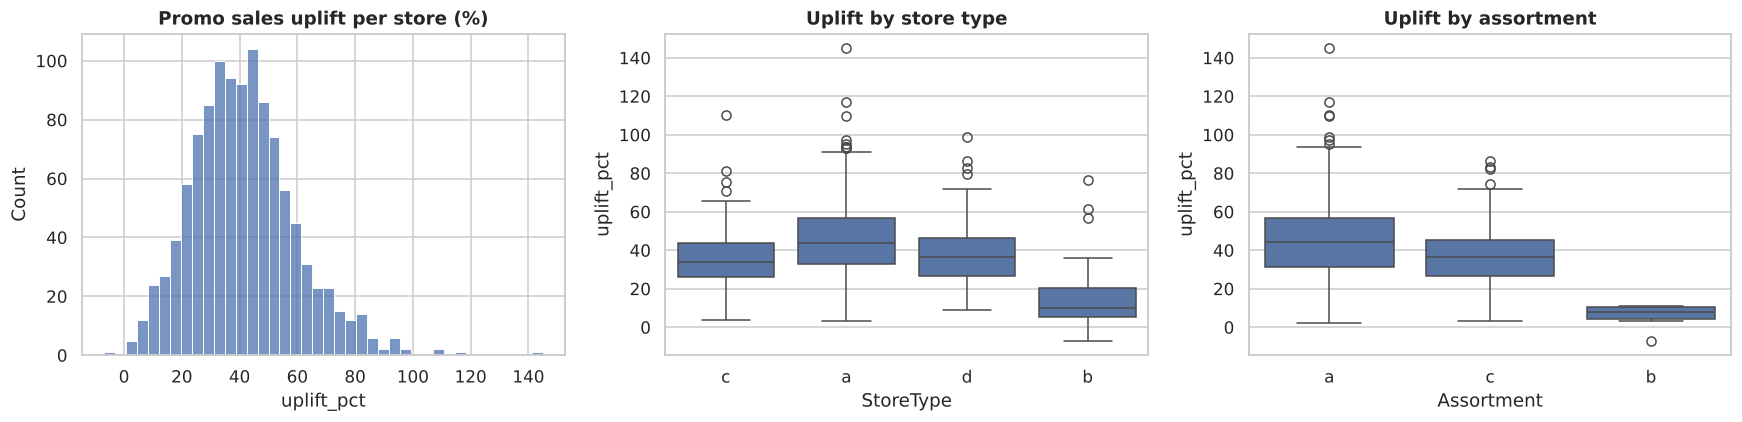

Top-10 uplift stores: {198: 145.0, 607: 117.0, 543: 110.0, 575: 110.0, 693: 99.0, 271: 97.0, 552: 95.0, 96: 94.0, 635: 94.0, 489: 93.0}
Lowest-10: {274: -7.0, 262: 2.0, 948: 3.0, 827: 3.0, 553: 4.0, 353: 4.0, 444: 5.0, 760: 5.0, 676: 6.0, 1075: 6.0}
{'a': 45.8, 'b': 19.1, 'c': 35.5, 'd': 37.5} {'a': 45.9, 'b': 6.3, 'c': 36.9}


In [9]:
# Where should promos be deployed? Uplift per store (promo vs non-promo average sales)
up = opn.groupby(["Store","Promo"]).Sales.mean().unstack(); up["uplift_pct"] = (up[1]/up[0]-1)*100
up = up.join(store.set_index("Store")[["StoreType","Assortment","Promo2","CompetitionDistance"]])
print(up.uplift_pct.describe().round(1))
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(up.uplift_pct, bins=40, ax=ax[0]); ax[0].set_title("Promo sales uplift per store (%)")
sns.boxplot(data=up, x="StoreType", y="uplift_pct", ax=ax[1]); ax[1].set_title("Uplift by store type")
sns.boxplot(data=up, x="Assortment", y="uplift_pct", ax=ax[2]); ax[2].set_title("Uplift by assortment")
save("07_promo_uplift_by_store")
print("Top-10 uplift stores:", up.uplift_pct.nlargest(10).round(0).to_dict()); print("Lowest-10:", up.uplift_pct.nsmallest(10).round(0).to_dict())
print(up.groupby("StoreType").uplift_pct.mean().round(1).to_dict(), up.groupby("Assortment").uplift_pct.mean().round(1).to_dict())

**Insight:**
- Promos only run **Mon-Fri** (~53% of those days). On open weekdays, promo days show **+39% sales, +20% customers and +15% spend per customer**. So promos both attract more customers and make existing ones spend more per visit.
- The effect is **strongest on Mondays (+57%) and shrinks to +22% on Friday**.
- **Promo2** stores sell about 13% less on average than non-Promo2 stores, and Promo2 being active shows a weak negative correlation with sales. The data can't tell whether Promo2 hurts or whether weaker stores were enrolled in it, so treat it cautiously.
- **Where to deploy:** median store uplift is +41% (range -7% to +145%). Uplift is highest for store type **a** (≈ +46%) and assortment **a** (≈ +46%), and lowest for type **b** (≈ +19%) and assortment **b** (≈ +6%), which already sell a lot. About ten stores gain ≤6%; promo budget there is better spent elsewhere. This is observational, not a controlled test.

## 5. Opening and closing patterns

Share of store-days open by weekday: {1: 95.0, 2: 98.8, 3: 97.4, 4: 92.3, 5: 95.1, 6: 99.5, 7: 2.5}


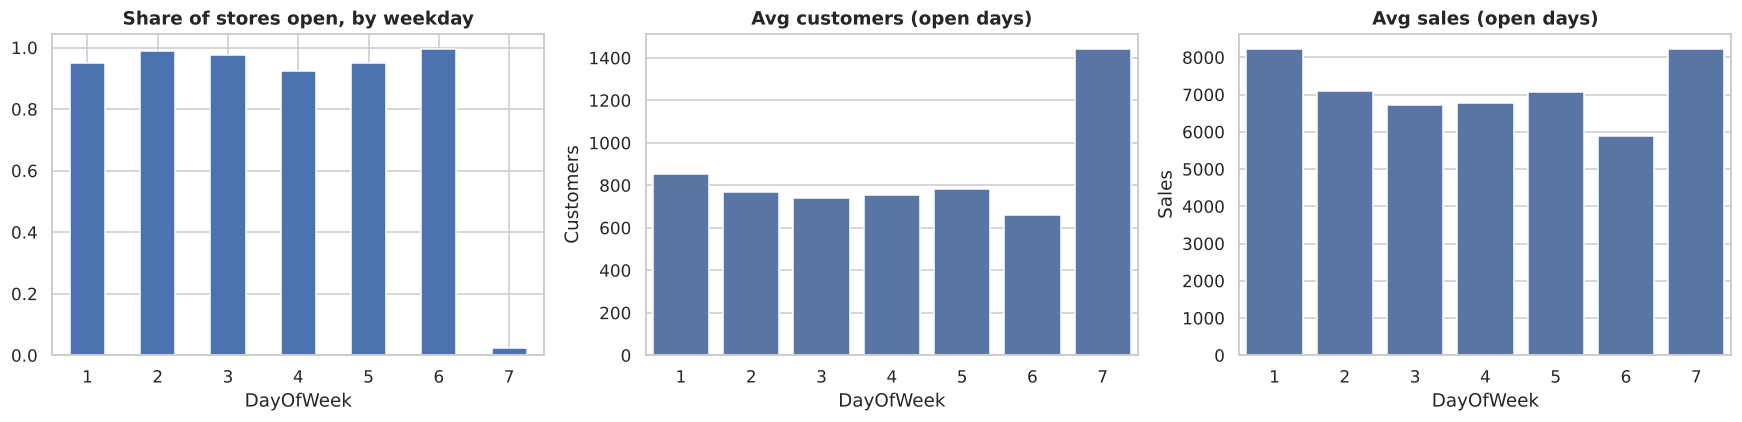

Non-holiday weekday closures: 1148 across 130 stores


Reopening day (n=254): avg sales 10245 vs 6699 normal Tue-Sat | indexed to store mean: 1.47 vs 0.96


In [10]:
cl = train.groupby("DayOfWeek").Open.mean(); print("Share of store-days open by weekday:", (cl*100).round(1).to_dict())
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
cl.plot(kind="bar", ax=ax[0], rot=0); ax[0].set_title("Share of stores open, by weekday")
sns.barplot(data=opn, x="DayOfWeek", y="Customers", ax=ax[1], errorbar=None); ax[1].set_title("Avg customers (open days)")
sns.barplot(data=opn, x="DayOfWeek", y="Sales", ax=ax[2], errorbar=None); ax[2].set_title("Avg sales (open days)")
save("08_weekday_open")
# Closures: stores closed on weekdays (refurbishment) and sales around them
closed_wd = train[(train.Open==0) & (train.DayOfWeek<=5) & (train.StateHoliday=="0") & (train.SchoolHoliday==0)]
print("Non-holiday weekday closures:", len(closed_wd), "across", closed_wd.Store.nunique(), "stores")
t = train.sort_values(["Store","Date"]).copy(); g_ = t.groupby("Store")
t["prev_closed_wd"] = (g_.Open.shift(1)==0) & (g_.DayOfWeek.shift(1)<=5) & (g_.StateHoliday.shift(1)=="0")   # yesterday: closed weekday, not a holiday
smean = t[t.Open==1].groupby("Store").Sales.mean(); t["idx"] = t.Sales / t.Store.map(smean)
after = t[(t.Open==1) & t.prev_closed_wd & t.DayOfWeek.between(2,6)]; normal = t[(t.Open==1) & ~t.prev_closed_wd & t.DayOfWeek.between(2,6) & (t.StateHoliday=="0")]
print(f"Reopening day (n={len(after)}): avg sales {after.Sales.mean():.0f} vs {normal.Sales.mean():.0f} normal Tue-Sat | indexed to store mean: {after.idx.mean():.2f} vs {normal.idx.mean():.2f}")

Stores that open on Sundays: 33 of 1115 | store types: {'b': 17, 'a': 13, 'd': 3}


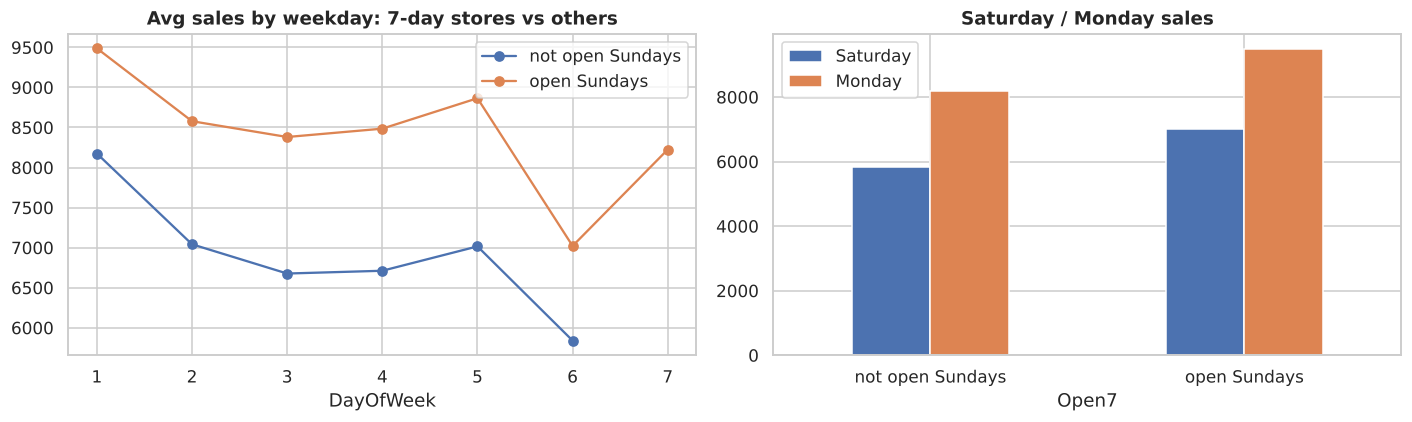

Stores open every Mon-Fri: 985 | with closures: 130
Avg Saturday sales: {'had closures': 6074.0, 'open all weekdays': 5864.0} | Saturday/weekday ratio: {'had closures': 0.819, 'open all weekdays': 0.817}
{False: 0.82, True: 0.81} (Saturday sales relative to the store's own weekday avg)


In [11]:
# Stores open on all 7 days vs others
sun_open = train[(train.DayOfWeek==7)&(train.Open==1)].Store.unique()
opn = opn.assign(Open7 = opn.Store.isin(sun_open))
print("Stores that open on Sundays:", len(sun_open), "of", train.Store.nunique(), "| store types:", store[store.Store.isin(sun_open)].StoreType.value_counts().to_dict())
wd = opn.groupby(["Open7","DayOfWeek"]).Sales.mean().unstack(0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4)); wd.plot(ax=ax[0], marker="o"); ax[0].set_title("Avg sales by weekday: 7-day stores vs others"); ax[0].legend(["not open Sundays","open Sundays"])
sat = opn[opn.DayOfWeek==6].groupby("Open7").Sales.mean(); mon = opn[opn.DayOfWeek==1].groupby("Open7").Sales.mean()
pd.DataFrame({"Saturday": sat, "Monday": mon}).rename(index={False:"not open Sundays",True:"open Sundays"}).plot(kind="bar", ax=ax[1], rot=0); ax[1].set_title("Saturday / Monday sales")
save("09_open_all_week")
# stores open on every Mon-Fri (no unexplained weekday closures) vs stores with closures
closed_stores = closed_wd.Store.unique(); full_wk = ~opn.Store.isin(closed_stores)
sat_s = opn[opn.DayOfWeek==6].groupby("Store").Sales.mean(); wk_s = opn[opn.DayOfWeek<=5].groupby("Store").Sales.mean()
fw = pd.Series(~sat_s.index.isin(closed_stores), index=sat_s.index)
print("Stores open every Mon-Fri:", int(fw.sum()), "| with closures:", int((~fw).sum()))
print("Avg Saturday sales:", sat_s.groupby(fw).mean().round(0).rename({True:"open all weekdays",False:"had closures"}).to_dict(), "| Saturday/weekday ratio:", (sat_s/wk_s).groupby(fw).mean().round(3).rename({True:"open all weekdays",False:"had closures"}).to_dict())
# like-for-like: compare each store's Saturday sales to its own weekday mean
rat = opn.assign(wkd=opn.DayOfWeek<=5).groupby(["Store","Open7","wkd"]).Sales.mean().unstack("wkd"); rat["sat_ratio"] = opn[opn.DayOfWeek==6].groupby("Store").Sales.mean() / rat[True]
print(rat.groupby("Open7").sat_ratio.mean().round(2).to_dict(), "(Saturday sales relative to the store's own weekday avg)")

**Insight:**
- **Sunday:** only ≈ 2.5% of store-days are open. 33 stores (mostly types b and a) open on Sundays.
- **Weekdays:** 130 stores had non-holiday weekday closures (e.g. refurbishment); the other 985 were open throughout. The **day a store reopens sells ≈ 47% above its norm** (n = 254), a pent-up-demand effect.
- **Weekend effect:** Saturday sales are ≈ 82% of weekday sales both for stores open all weekdays and for stores with closures, and Sunday-opening stores show the same ratio (0.81). **Opening on more days does not cannibalise Saturday sales.**
- The data has **no hour-level information**, so opening/closing *times* within a day cannot be analysed. Only open/closed days are available.

## 6. Assortment type

                sales  customers    spc  stores
a (basic)     6621.52     748.00   9.13     593
b (extra)     8642.50    2067.55   4.16       9
c (extended)  7300.84     752.20  10.02     513


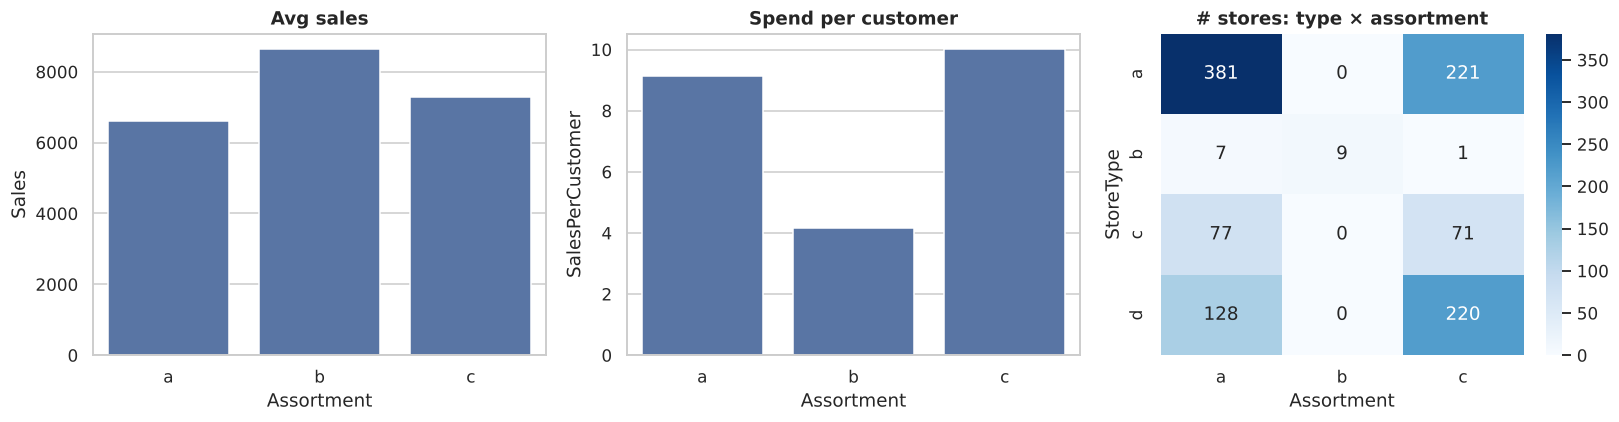

Assortment        a       b        c
StoreType                           
a            6538.0     NaN   7574.0
b           11134.0  8643.0  17970.0
c            6836.0     NaN   7038.0
d            6434.0     NaN   7044.0


In [12]:
a = opn.groupby("Assortment").agg(sales=("Sales","mean"), customers=("Customers","mean"), spc=("SalesPerCustomer","mean"), stores=("Store","nunique")).round(2); a.index = ["a (basic)","b (extra)","c (extended)"]; print(a)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=opn, x="Assortment", y="Sales", ax=ax[0], errorbar=None, order=list("abc")); ax[0].set_title("Avg sales")
sns.barplot(data=opn, x="Assortment", y="SalesPerCustomer", ax=ax[1], errorbar=None, order=list("abc")); ax[1].set_title("Spend per customer")
sns.heatmap(pd.crosstab(store.StoreType, store.Assortment), annot=True, fmt="d", cmap="Blues", ax=ax[2]); ax[2].set_title("# stores: type × assortment")
save("10_assortment"); print(opn.groupby(["StoreType","Assortment"]).Sales.mean().round(0).unstack().to_string())

**Insight:** Extra assortment (b) shows the highest average sales (≈ 8.6k) but covers only **9 stores, all of store type b**, with very low spend per customer, so it can't be generalised. Within the larger groups, **extended (c) beats basic (a)**: ≈ +16% for type a, +9% for type d and +3% for type c. Assortment is strongly tied to store type, so the two should be modelled together.

## 7. Competition

           sales  customers  stores
DistBin                            
<500m     7611.0      969.0     220
500m-1km  6677.0      835.0     110
1-2.5km   6855.0      754.0     250
2.5-5km   6791.0      706.0     186
5-10km    6743.0      630.0     162
>10km     6825.0      660.0     187
Corr(distance, store avg sales): -0.042 (Spearman -0.028)


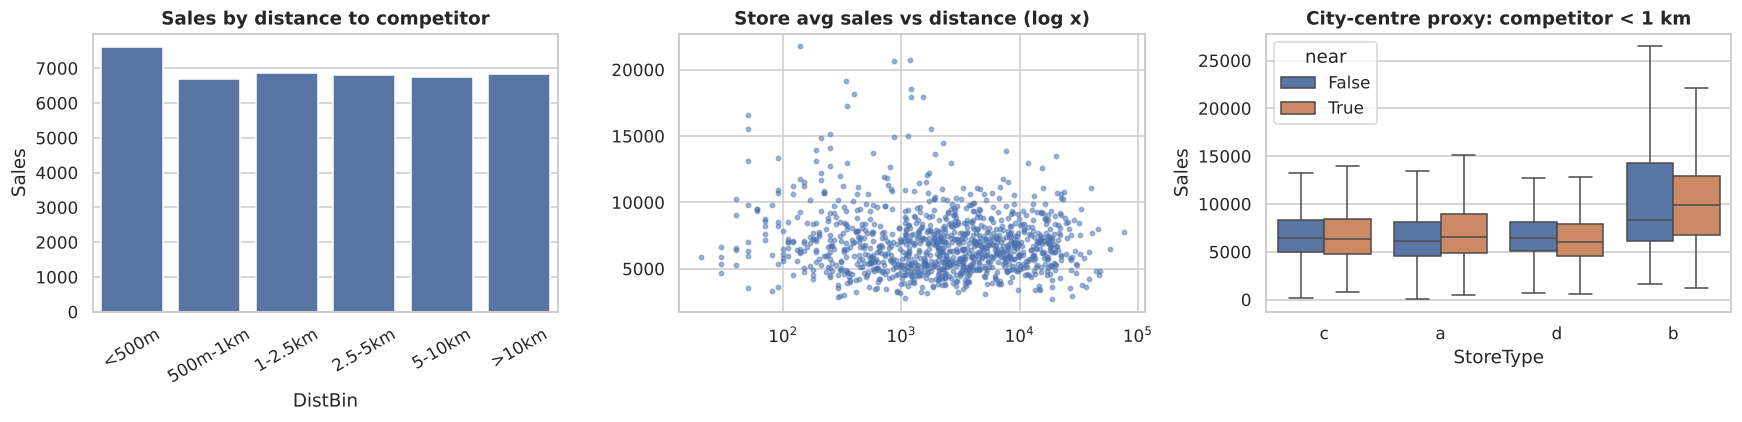

{False: {'a': 6632.0, 'b': 10417.0, 'c': 6933.0, 'd': 6873.0}, True: {'a': 7435.0, 'b': 10063.0, 'c': 6934.0, 'd': 6470.0}}


In [13]:
opn = opn.assign(DistBin = pd.cut(opn.CompetitionDistance, [0, 500, 1000, 2500, 5000, 10000, 100000], labels=["<500m","500m-1km","1-2.5km","2.5-5km","5-10km",">10km"]))
d = opn.groupby("DistBin").agg(sales=("Sales","mean"), customers=("Customers","mean"), stores=("Store","nunique")).round(0); print(d)
sm = opn.groupby("Store").agg(Sales=("Sales","mean"), dist=("CompetitionDistance","first")); print("Corr(distance, store avg sales): %.3f (Spearman %.3f)" % (sm.Sales.corr(sm.dist), sm.Sales.corr(sm.dist, method="spearman")))
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(data=opn, x="DistBin", y="Sales", ax=ax[0], errorbar=None); ax[0].set_title("Sales by distance to competitor"); ax[0].tick_params(axis="x", rotation=30)
ax[1].scatter(sm.dist, sm.Sales, s=8, alpha=.5); ax[1].set_xscale("log"); ax[1].set_title("Store avg sales vs distance (log x)")
sns.boxplot(data=opn.assign(near=opn.CompetitionDistance<1000), x="StoreType", y="Sales", hue="near", ax=ax[2], showfliers=False); ax[2].set_title("City-centre proxy: competitor < 1 km")
save("11_competition_distance")
print(opn.assign(near=opn.CompetitionDistance<1000).groupby(["StoreType","near"]).Sales.mean().round(0).unstack().to_dict())

Stores whose competitor opened inside the window: 121


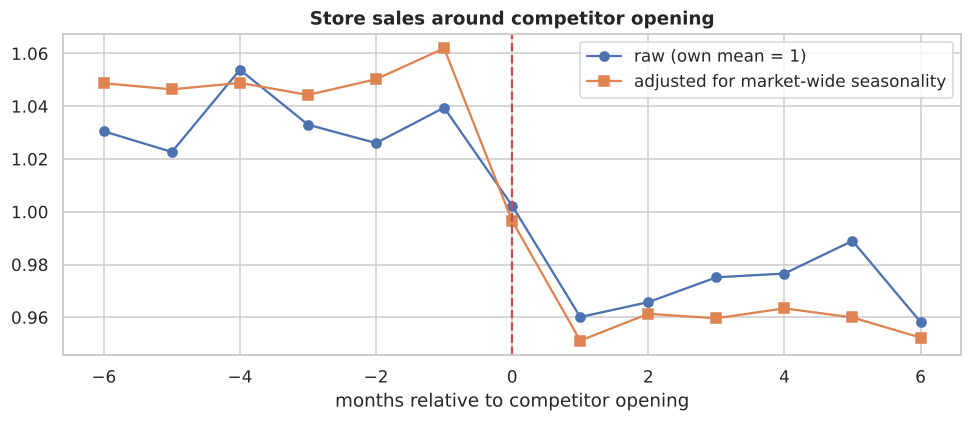

6m before vs 6m after | raw: 1.034 -> 0.971 | adjusted: 1.050 -> 0.958
Stores with NA distance:
 Store StoreType  CompetitionOpenSinceYear
   291         d                       NaN
   622         a                       NaN
   879         d                       NaN
Competitor open year distribution: {2010: 55, 2011: 54, 2012: 82, 2013: 83, 2014: 70, 2015: 38}


In [14]:
# Competitor opening effect: stores whose competitor opened inside the data window
w = store[(store.HasCompetitionDate==1)]; w = w.assign(open_dt = pd.to_datetime(dict(year=w.CompetitionOpenSinceYear, month=w.CompetitionOpenSinceMonth, day=1)))
w = w[(w.open_dt >= "2013-07-01") & (w.open_dt <= "2015-01-31")]   # ≥6 months of data on each side
print("Stores whose competitor opened inside the window:", len(w))
ev = opn[opn.Store.isin(w.Store)].merge(w[["Store","open_dt"]], on="Store")
ev["rel_m"] = ((ev.Date.dt.year - ev.open_dt.dt.year)*12 + ev.Date.dt.month - ev.open_dt.dt.month); ev = ev[ev.rel_m.between(-6, 6)]
smean = opn.groupby("Store").Sales.mean(); sn = opn.Sales / opn.Store.map(smean)                     # store-indexed sales
market = sn.groupby([opn.Year, opn.Month]).mean()                                                       # all-store monthly level (removes seasonality/trend)
ev["raw"] = ev.Sales / ev.Store.map(smean); ev["adj"] = ev.raw / pd.MultiIndex.from_arrays([ev.Year, ev.Month]).map(market).values
p = ev.groupby("rel_m")[["raw","adj"]].mean()
fig, ax = plt.subplots(figsize=(9, 4)); ax.plot(p.index, p.raw, marker="o", label="raw (own mean = 1)"); ax.plot(p.index, p.adj, marker="s", label="adjusted for market-wide seasonality"); ax.axvline(0, c="r", ls="--"); ax.legend(); ax.set_title("Store sales around competitor opening"); ax.set_xlabel("months relative to competitor opening")
save("12_competitor_opening")
print("6m before vs 6m after | raw: %.3f -> %.3f | adjusted: %.3f -> %.3f" % (p.raw.loc[-6:-1].mean(), p.raw.loc[1:6].mean(), p.adj.loc[-6:-1].mean(), p.adj.loc[1:6].mean()))
na = store_raw[store_raw.CompetitionDistance.isna()][["Store","StoreType","CompetitionOpenSinceYear"]]; print("Stores with NA distance:"); print(na.to_string(index=False))
print("Competitor open year distribution:", store_raw.CompetitionOpenSinceYear.dropna().astype(int).value_counts().sort_index().tail(6).to_dict())

**Insight:**
- **Distance** has almost no linear relationship with a store's average sales (r ≈ -0.04). Stores with a competitor **< 500 m away actually sell the most** (≈ 7.6k, ≈ 970 customers). Those are likely busy city-centre locations where footfall outweighs competition.
- **City-centre proxy** (competitor < 1 km): store type a sells ≈ +12% more when the competitor is near, while other types show no real difference. The data has no city information, so this is only a proxy.
- **Competitor opening:** for 121 stores whose competitor opened inside the data window, sales fall about **8-9% after the opening** (adjusted index ≈ 1.05 before vs ≈ 0.96 after). The opening month is approximate and part of this may be mean reversion, but the step is consistent.
- **Missing distance:** only 3 stores (291, 622, 879) have NA distance, and none ever gets a value because `store.csv` is a single snapshot with no history. We fill with the median plus a flag.

## 8. Correlations and engineered features

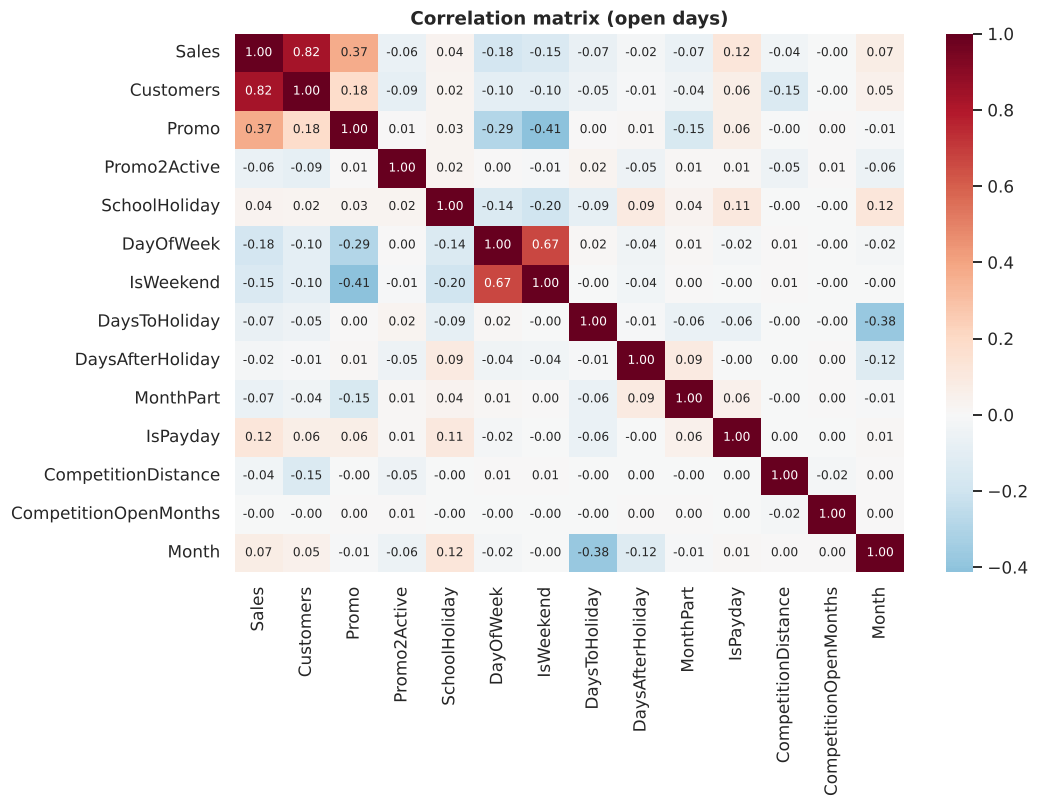

{'DayOfWeek': -0.18, 'IsWeekend': -0.15, 'DaysToHoliday': -0.07, 'MonthPart': -0.07, 'Promo2Active': -0.06, 'CompetitionDistance': -0.04, 'DaysAfterHoliday': -0.02, 'CompetitionOpenMonths': -0.0, 'SchoolHoliday': 0.04, 'Month': 0.07, 'IsPayday': 0.12, 'Promo': 0.37, 'Customers': 0.82}


In [15]:
cols = ["Sales","Customers","Promo","Promo2Active","SchoolHoliday","DayOfWeek","IsWeekend","DaysToHoliday","DaysAfterHoliday","MonthPart","IsPayday","CompetitionDistance","CompetitionOpenMonths","Month"]
fig, ax = plt.subplots(figsize=(10, 7.5)); sns.heatmap(opn[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, annot_kws={"size": 8}); ax.set_title("Correlation matrix (open days)")
save("13_correlation"); print(opn[cols].corr().Sales.drop("Sales").sort_values().round(2).to_dict())

**Insight:** Beyond `Customers` (0.82, unavailable at test time), the strongest linear drivers are **Promo (+0.37)**, **DayOfWeek (-0.18, Monday highest, weekend lower)**, **IsPayday (+0.12)** and Month (+0.07, the December effect). Competition distance and Promo2 are weak linearly, though tree models may still use them. The engineered holiday and month-position features add modest signal.

## Summary and next steps

**Key takeaways**
1. Promo is the biggest controllable lever (+39% sales on weekdays), strongest on Mondays and for store types a, c and d; low-return stores (type b and assortment b) are poor promo targets.
2. Strong seasonality: December peak, pre-holiday run-up, and stores are closed on holidays and Sundays. Within a store, promo and weekday are the main drivers; the store's own sales level explains most of the overall variation (confirmed by the model's feature importance).
3. Sales are driven by footfall (r = 0.82), but customers must be predicted separately because it's absent in the test set.
4. A new competitor reduces sales by roughly 8-9%; distance alone barely matters.
5. Test window is a 6-week out-of-time period with many more school holidays, so validate with a time-based split.

**Worth further investigation: yes.** Store level, promo and weekday carry strong signal for the forecasting task.

**Outputs:** cleaned/feature data → `data/processed/*.pkl` (via `python -m src.build_dataset`), figures → `figures/`, logs → `logs/rossmann.log`.

Next: modelling (Task 2) with these engineered features.